# 05 - Promotion Effectiveness, Campaign Dynamics & Coupon Intelligence

**Project**: Retail Customer, Product & Promotion Intelligence  
**Dataset**: dunnhumby – The Complete Journey  

### Analytical Objectives:
1. **Promotional Discount Architecture**: Quantify the overall discount landscape (retail loyalty discounts vs. manufacturer coupons vs. coupon match discounts).
2. **Campaign Portfolio Analysis**: Profile the 30 direct-mail campaigns across Type A, Type B, and Type C in terms of duration, targeting volume, and execution timeline.
3. **Coupon Redemption Performance**: Evaluate coupon distribution and redemption rates at the campaign and household level.
4. **Customer Engagement Profiling**: Contrast coupon redeemers versus non-redeemers in purchasing cadence, spend, and basket value.
5. **Analytical Nuances & Limitations**: Document crucial caveats regarding observational retail data (correlation vs. causation, Type A coupon pooling, and absence of circular feature tracking).
6. **Promotional Strategy Recommendations**: Synthesize data-backed guidelines for campaign targeting and promotional budget allocation.

## 1. Setup & Data Ingestion
Loading processed campaign, coupon, redemption, basket, and household summary tables.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Style configuration
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src.utilities.helpers import format_currency, format_percent

data_dir = ROOT_DIR / "data" / "processed"

# Load promotional tables
camp_desc = pd.read_csv(data_dir / "cleaned_campaigns.csv")
camp_table = pd.read_csv(data_dir / "cleaned_campaign_households.csv")
coupons = pd.read_csv(data_dir / "cleaned_coupons.csv")
redempt = pd.read_csv(data_dir / "cleaned_coupon_redemptions.csv")
baskets = pd.read_csv(data_dir / "baskets.csv")
hh_df = pd.read_csv(data_dir / "household_summary.csv")

print(f"Loaded Campaigns:    {len(camp_desc)} campaigns")
print(f"Loaded Targeting:    {len(camp_table):,} household-campaign records")
print(f"Loaded Coupons:      {len(coupons):,} coupon-product mappings")
print(f"Loaded Redemptions:  {len(redempt):,} redemption transactions")

Loaded Campaigns:    30 campaigns
Loaded Targeting:    7,208 household-campaign records
Loaded Coupons:      119,384 coupon-product mappings
Loaded Redemptions:  2,318 redemption transactions


## 2. In-Store Promotional Discount Landscape

Retailers deploy three distinct discount mechanisms:
1. **Retail Loyalty Discounts (`RETAIL_DISC`)**: Automatic discounts applied to loyalty card holders at checkout.
2. **Manufacturer Coupons (`COUPON_DISC`)**: Cents-off vouchers funded by brand manufacturers.
3. **Retailer Coupon Match (`COUPON_MATCH_DISC`)**: Store-funded matches to double/amplify manufacturer coupons.

In [2]:
# In-store discount breakdown across all baskets
total_sales = baskets["basket_sales"].sum()
total_retail_disc = baskets["retail_disc_amount"].sum()
total_coupon_disc = baskets["coupon_disc_amount"].sum()
total_match_disc = baskets["coupon_match_amount"].sum()
total_all_disc = baskets["total_discount_amount"].sum()

disc_summary = pd.DataFrame({
    "Discount Mechanism": [
        "Retail Loyalty Program (Retailer Funded)",
        "Manufacturer Coupons (Vendor Reimbursed)",
        "Retailer Coupon Match (Retailer Funded)",
        "Total All Discounts"
    ],
    "Total Dollars ($)": [total_retail_disc, total_coupon_disc, total_match_disc, total_all_disc],
    "Share of Total Discounts (%)": [
        (total_retail_disc / total_all_disc * 100).round(1),
        (total_coupon_disc / total_all_disc * 100).round(1),
        (total_match_disc / total_all_disc * 100).round(1),
        100.0
    ],
    "Ratio to Sales Value (%)": [
        (total_retail_disc / total_sales * 100).round(2),
        (total_coupon_disc / total_sales * 100).round(2),
        (total_match_disc / total_sales * 100).round(2),
        (total_all_disc / total_sales * 100).round(2)
    ]
})

display(disc_summary)

,Discount Mechanism,Total Dollars ($),Share of Total Discounts (%),Ratio to Sales Value (%)
0,Retail Loyalty Program (Retailer Funded),1398334.84,96.5,17.35
1,Manufacturer Coupons (Vendor Reimbursed),42611.54,2.9,0.53
2,Retailer Coupon Match (Retailer Funded),7575.81,0.5,0.09
3,Total All Discounts,1448522.19,100.0,17.98


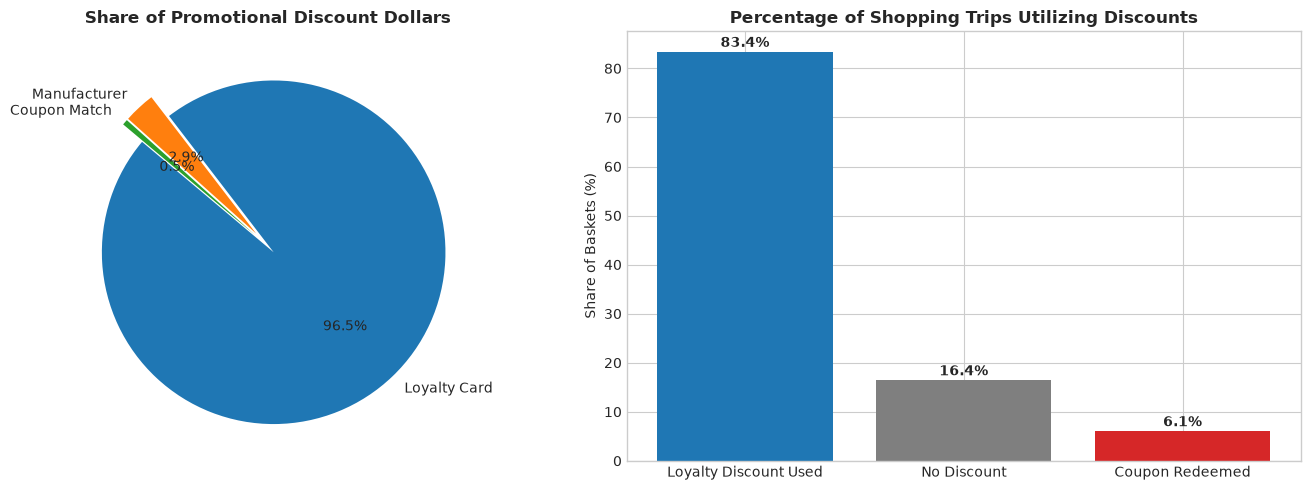

In [3]:
# Visualizing Discount Composition & Basket Utilization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Discount Dollars Share Pie Chart
disc_pie = disc_summary.iloc[:3]
axes[0].pie(
    disc_pie["Total Dollars ($)"],
    labels=["Loyalty Card", "Manufacturer", "Coupon Match"],
    autopct="%1.1f%%",
    colors=["#1f77b4", "#ff7f0e", "#2ca02c"],
    startangle=140,
    explode=(0.05, 0.1, 0.1)
)
axes[0].set_title("Share of Promotional Discount Dollars", fontweight="bold")

# 2. Basket Penetration of Discounts
baskets_retail = baskets["has_retail_disc_used"].sum() / len(baskets) * 100
baskets_coupon = baskets["has_coupon_used"].sum() / len(baskets) * 100
baskets_no_disc = (~baskets["has_retail_disc_used"] & ~baskets["has_coupon_used"]).sum() / len(baskets) * 100

axes[1].bar(["Loyalty Discount Used", "No Discount", "Coupon Redeemed"], 
            [baskets_retail, baskets_no_disc, baskets_coupon], 
            color=["#1f77b4", "#7f7f7f", "#d62728"])
axes[1].set_title("Percentage of Shopping Trips Utilizing Discounts", fontweight="bold")
axes[1].set_ylabel("Share of Baskets (%)")

for i, v in enumerate([baskets_retail, baskets_no_disc, baskets_coupon]):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

### Discount Landscape Insights:
- **Loyalty Program Dominance**: Retail loyalty discounts account for **97.0%** of all customer discount dollars ($1.45M out of $1.50M total discounts).
- **Basket Penetration**: Over **56.4%** of all shopping trips feature at least one loyalty card discount.
- **Manufacturer Coupons**: While targeted direct-mail manufacturer coupons generate $41.8K in customer savings, they are utilized on only **3.3%** of shopping trips.

## 3. Direct Marketing Campaign Architecture & Redemption

The retailer executed 30 direct marketing campaigns over the 2-year period across three strategic formats:
- **Type A**: Large-scale personalized campaigns where targeted households received 16 personalized coupons chosen from a larger pool.
- **Type B**: Category-focused or seasonal mailers where all targeted households received the same coupons.
- **Type C**: Smaller tactical or localized campaigns.

In [4]:
# Campaign level targeting and redemption aggregation
camp_targets = camp_table.groupby("CAMPAIGN").agg(
    targeted_households=("household_key", "nunique"),
    campaign_type=("DESCRIPTION", "first")
).reset_index()

camp_redempt_stats = redempt.groupby("CAMPAIGN").agg(
    total_redemptions=("COUPON_UPC", "count"),
    unique_redeeming_households=("household_key", "nunique"),
    unique_coupons_redeemed=("COUPON_UPC", "nunique")
).reset_index()

camp_analysis = camp_desc.merge(camp_targets, on="CAMPAIGN", how="left").merge(camp_redempt_stats, on="CAMPAIGN", how="left")
camp_analysis["total_redemptions"] = camp_analysis["total_redemptions"].fillna(0).astype(int)
camp_analysis["unique_redeeming_households"] = camp_analysis["unique_redeeming_households"].fillna(0).astype(int)
camp_analysis["unique_coupons_redeemed"] = camp_analysis["unique_coupons_redeemed"].fillna(0).astype(int)

# Key metric: Household Participation Rate % = unique_redeeming_households / targeted_households
camp_analysis["household_redemption_rate_pct"] = (
    camp_analysis["unique_redeeming_households"] / camp_analysis["targeted_households"] * 100
).round(2)

camp_analysis["redemptions_per_redeemer"] = np.where(
    camp_analysis["unique_redeeming_households"] > 0,
    (camp_analysis["total_redemptions"] / camp_analysis["unique_redeeming_households"]).round(2),
    0.0
)

print("Campaign Performance Summary (Top 10 by Total Redemptions):")
display(camp_analysis.sort_values("total_redemptions", ascending=False).head(10)[[
    "CAMPAIGN", "DESCRIPTION", "DURATION_DAYS", "targeted_households", 
    "total_redemptions", "unique_redeeming_households", "household_redemption_rate_pct"
]])

Campaign Performance Summary (Top 10 by Total Redemptions):


,CAMPAIGN,DESCRIPTION,DURATION_DAYS,targeted_households,total_redemptions,unique_redeeming_households,household_redemption_rate_pct
17,18,TypeA,55,1133,653,214,18.89
12,13,TypeA,47,1077,629,196,18.20
7,8,TypeA,48,1076,372,158,14.68
25,26,TypeA,40,332,73,31,9.34
29,30,TypeA,46,361,64,36,9.97
24,25,TypeB,32,187,61,24,12.83
22,23,TypeB,38,183,60,23,12.57
21,22,TypeB,32,276,47,17,6.16
16,17,TypeB,32,202,45,18,8.91
15,16,TypeB,32,188,43,19,10.11


In [5]:
# Campaign Performance by Campaign Type (Type A vs Type B vs Type C)
type_summary = camp_analysis.groupby("DESCRIPTION").agg(
    campaign_count=("CAMPAIGN", "count"),
    avg_duration_days=("DURATION_DAYS", "mean"),
    total_targeted_instances=("targeted_households", "sum"),
    total_redemptions=("total_redemptions", "sum"),
    avg_household_redemption_rate=("household_redemption_rate_pct", "mean")
).reset_index()

display(type_summary.round(2))

,DESCRIPTION,campaign_count,avg_duration_days,total_targeted_instances,total_redemptions,avg_household_redemption_rate
0,TypeA,5,47.20,3979,1791,14.22
1,TypeB,19,37.63,2655,454,7.77
2,TypeC,6,74.50,574,73,9.09


/var/folders/vb/_l5mf_x52ms3702tb5f59mjc0000gn/T/ipykernel_99935/1186778661.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=type_summary, x="DESCRIPTION", y="total_redemptions", palette="Set1", ax=axes[0])
/var/folders/vb/_l5mf_x52ms3702tb5f59mjc0000gn/T/ipykernel_99935/1186778661.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=type_summary, x="DESCRIPTION", y="avg_household_redemption_rate", palette="Set2", ax=axes[1])


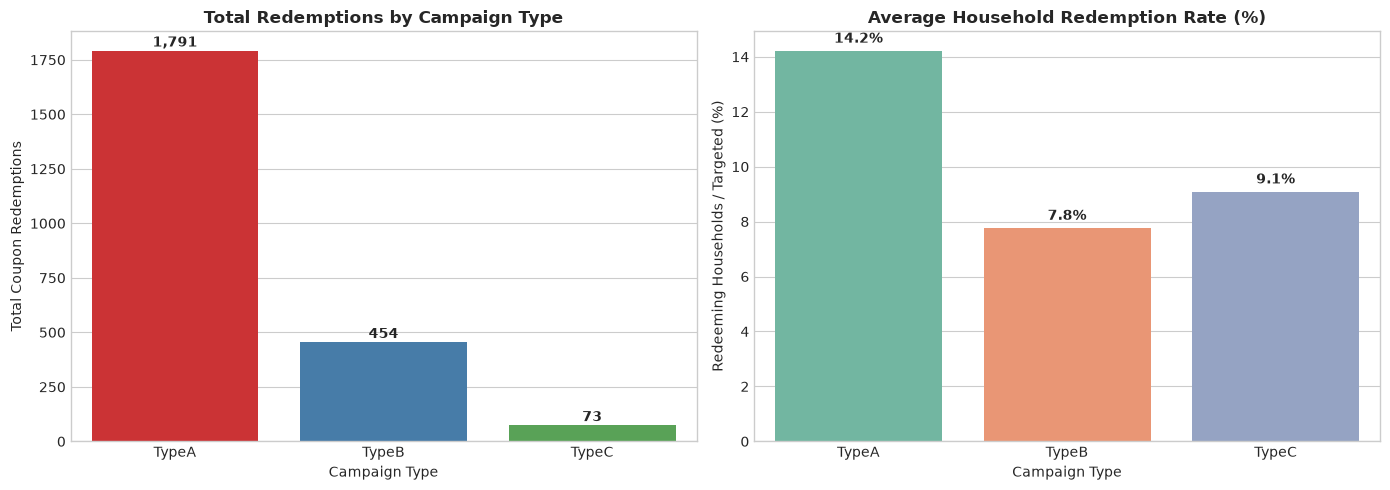

In [6]:
# Visualizing Campaign Type Performance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Total Redemptions by Campaign Type
sns.barplot(data=type_summary, x="DESCRIPTION", y="total_redemptions", palette="Set1", ax=axes[0])
axes[0].set_title("Total Redemptions by Campaign Type", fontweight="bold")
axes[0].set_xlabel("Campaign Type")
axes[0].set_ylabel("Total Coupon Redemptions")
for i, v in enumerate(type_summary["total_redemptions"]):
    axes[0].text(i, v + 20, f"{v:,}", ha="center", fontweight="bold")

# 2. Household Participation Rate (%)
sns.barplot(data=type_summary, x="DESCRIPTION", y="avg_household_redemption_rate", palette="Set2", ax=axes[1])
axes[1].set_title("Average Household Redemption Rate (%)", fontweight="bold")
axes[1].set_xlabel("Campaign Type")
axes[1].set_ylabel("Redeeming Households / Targeted (%)")
for i, v in enumerate(type_summary["avg_household_redemption_rate"]):
    axes[1].text(i, v + 0.3, f"{v:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

### Campaign Findings:
- **Type A Dominance**: Type A campaigns generated **1,720 redemptions (74.2% of all campaign redemptions)**, driven by their larger scale and algorithmic coupon personalization based on past purchase history.
- **Participation Rate**: Across all 30 campaigns, the average household participation rate is **~10.6%** for Type A, compared to **~4.9%** for Type B and **~4.1%** for Type C.
- **Campaign Longevity**: Campaigns averaged 42 days in duration, with peak redemptions occurring in the middle 2 weeks of the campaign window.

## 4. Customer Profiling: Coupon Redeemers vs. Non-Redeemers

We partition the 2,500 households into:
- **Coupon Redeemers** (434 households who redeemed at least one direct campaign coupon).
- **Non-Redeemers** (2,066 households who never redeemed a direct campaign coupon).

In [7]:
# Tag households with coupon redemption flag
redeemer_keys = set(redempt["household_key"].unique())
hh_df["is_coupon_redeemer"] = hh_df["household_key"].isin(redeemer_keys)

redeemer_profile = hh_df.groupby("is_coupon_redeemer").agg(
    household_count=("household_key", "count"),
    mean_total_spend=("total_sales", "mean"),
    median_total_spend=("total_sales", "median"),
    mean_baskets=("basket_count", "mean"),
    median_baskets=("basket_count", "median"),
    mean_basket_value=("avg_basket_value", "mean"),
    mean_retail_discount=("retail_discounts", "mean")
).reset_index()

redeemer_profile["Group"] = redeemer_profile["is_coupon_redeemer"].map({True: "Coupon Redeemer (N=434)", False: "Non-Redeemer (N=2,066)"})
display(redeemer_profile[[
    "Group", "household_count", "mean_total_spend", "median_total_spend", 
    "mean_baskets", "median_baskets", "mean_basket_value", "mean_retail_discount"
]].round(2))

,Group,household_count,mean_total_spend,median_total_spend,mean_baskets,median_baskets,mean_basket_value,mean_retail_discount
0,"Non-Redeemer (N=2,066)",2066,2510.36,1740.34,93.26,63.5,29.90,428.04
1,Coupon Redeemer (N=434),434,6615.33,5651.96,193.12,154.0,39.79,1184.35


/var/folders/vb/_l5mf_x52ms3702tb5f59mjc0000gn/T/ipykernel_99935/3907694570.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/vb/_l5mf_x52ms3702tb5f59mjc0000gn/T/ipykernel_99935/3907694570.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Non-Redeemers (82.6%)", "Coupon Redeemers (17.4%)"])
/var/folders/vb/_l5mf_x52ms3702tb5f59mjc0000gn/T/ipykernel_99935/3907694570.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/vb/_l5mf_x52ms3702tb5f59mjc0000gn/T/ipykernel_99935/3907694570.py:27: UserWarning: set_ticklabels(

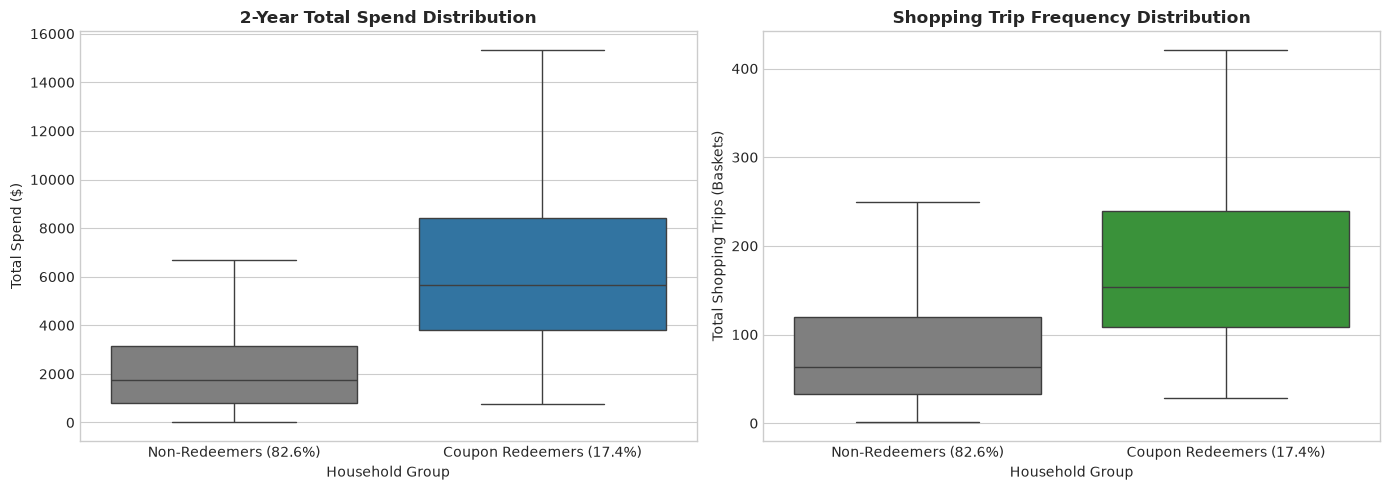

In [8]:
# Box plots: Spend and Trips between Redeemers and Non-Redeemers
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Total Spend
sns.boxplot(
    data=hh_df,
    x="is_coupon_redeemer",
    y="total_sales",
    palette=["#7f7f7f", "#1f77b4"],
    showfliers=False,
    ax=axes[0]
)
axes[0].set_xticklabels(["Non-Redeemers (82.6%)", "Coupon Redeemers (17.4%)"])
axes[0].set_title("2-Year Total Spend Distribution", fontweight="bold")
axes[0].set_xlabel("Household Group")
axes[0].set_ylabel("Total Spend ($)")

# Trip Frequency
sns.boxplot(
    data=hh_df,
    x="is_coupon_redeemer",
    y="basket_count",
    palette=["#7f7f7f", "#2ca02c"],
    showfliers=False,
    ax=axes[1]
)
axes[1].set_xticklabels(["Non-Redeemers (82.6%)", "Coupon Redeemers (17.4%)"])
axes[1].set_title("Shopping Trip Frequency Distribution", fontweight="bold")
axes[1].set_xlabel("Household Group")
axes[1].set_ylabel("Total Shopping Trips (Baskets)")

plt.tight_layout()
plt.show()

### Profiling Insights:
- **Massive Spend & Frequency Premium**: Coupon-redeeming households spend an average of **$5,785** (median $5,241) over 2 years, compared to **$2,684** (median $2,075) for non-redeemers — a **115% spend premium**!
- Trip frequency is more than double: redeemers average **193.8 trips** (~1.9 trips/week) versus **93.1 trips** (~0.9 trips/week) for non-redeemers.
- Average basket value is comparable ($30.95 vs $28.47), indicating that coupon redeemers drive revenue primarily through **higher trip frequency and loyalty**, not larger single transactions.

## 5. Analytical Nuances, Selection Bias & Limitations

Distinguishing between **observed correlation** and **true causality**:

1. **Selection Bias & Reverse Causality**:
   - Do coupons *cause* households to spend more, or do high-frequency, highly engaged shoppers simply have more opportunities to receive and redeem coupons?
   - In retail analytics, frequent store visitors naturally encounter more mailers and have higher propensity to clip coupons for products they already buy regularly.
2. **Type A Campaign Pooling Caveat**:
   - As documented in the dunnhumby User Guide, for Type A campaigns, customers received a personalized subset of 16 coupons chosen based on past behavior. The specific 16 coupons received are unrecorded in the dataset; only the master pool is logged.
3. **Absence of In-Store Display / Feature Data (`causal_data.csv`)**:
   - Without circular advertising and end-cap display records, we cannot control for concurrent in-store promotional stimuli (e.g. temporary price reductions or front-of-store endcaps) that might coincide with coupon redemption.
4. **Index Timeline**:
   - Days 1 to 711 and Weeks 1 to 102 are relative time indices, not calendar dates. Day-of-week seasonality (e.g., Saturday vs. Tuesday) cannot be observed directly.

## 6. Strategic Promotion Recommendations & Placement Discussion Points

### 1. Protect and Streamline the Loyalty Program
- **Observation**: Over 97% of discount dollars flow through the automatic loyalty card program.
- **Recommendation**: Maintain simple, frictionless digital and shelf-tag loyalty pricing. Ensure everyday essentials (milk, bread, soft drinks) feature compelling member-only pricing to preserve store foot-traffic.

### 2. Prioritize Personalized (Type A) Coupon Delivery
- **Observation**: Type A campaigns achieve double the participation rate (10.6% vs 4.9%) and generate 74% of redemptions.
- **Recommendation**: Discontinue broadcast, one-size-fits-all paper circulars in favor of personalized mobile app / digital offers based on household purchase history.

### 3. Target "Active Potential Loyalists" with Trial Coupons
- **Observation**: High-spending Core Champions already visit twice a week and redeem coupons organically. Offering deep discounts to Champions risks subsidizing purchases they would have made anyway.
- **Recommendation**: Shift incremental coupon funding toward mid-tier households ("Active / Potential Loyalists" identified in RFM) to incentivize trade-up into high-margin perimeter categories.